# Post-transition overhead and recommendation funding

Run All to read the simplified Excel budget and display/export the graph. The top bar is annual post-transition overhead. The second bar divides the same amount between the cash-conversion target for recommendations and the overhead left after that hypothetical reduction.

This is a funding illustration, not confirmed savings or available cash. The project funding amount covers December 2026?December 2027, including the buffer; its percentage compares that project amount with one year of overhead. The graph intentionally has no title, subtitles or footnotes.

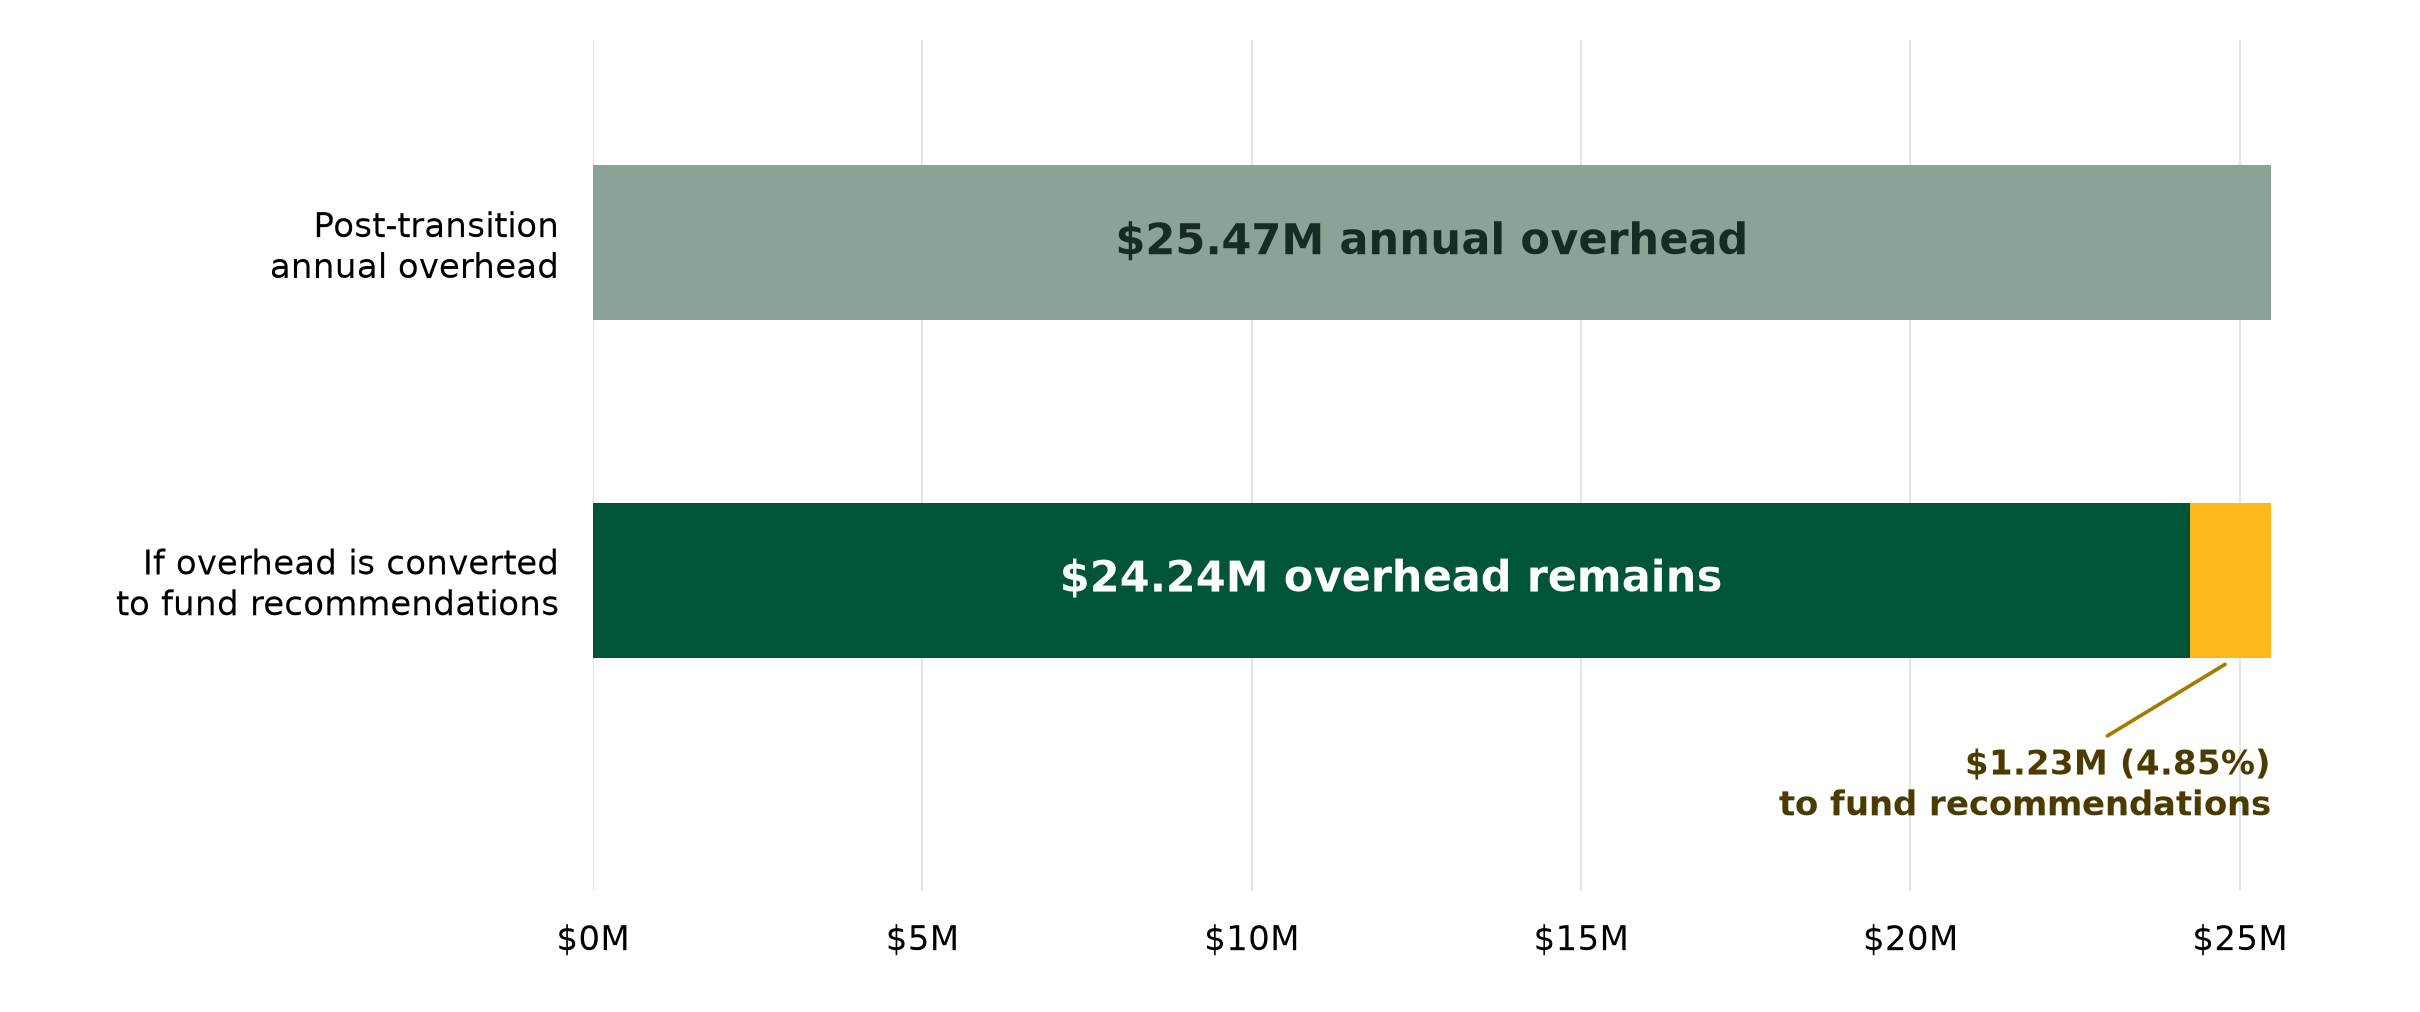

In [1]:
from pathlib import Path
from openpyxl import load_workbook
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import Image, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis_outputs/recommendation_costs/IEHP_Simple_Transition_Budget.xlsx").exists())
wb = load_workbook(root / "analysis_outputs/recommendation_costs/IEHP_Simple_Transition_Budget.xlsx", data_only=True)
s = wb["Simple Budget"]
overhead, recommendations = [float(s[c].value) for c in ("B11", "B26")]
wb.close()
remaining = overhead - recommendations
share = recommendations / overhead
assert 0 < recommendations < overhead
assert abs(remaining + recommendations - overhead) < .01
out = root / "analysis_outputs/slide_exports/overhead_redesign"
out.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 4.6))
green, muted, gold = "#005538", "#8BA396", "#FFB81C"
ax.barh(1, overhead/1e6, height=.46, color=muted, zorder=3)
ax.barh(0, remaining/1e6, height=.46, color=green, zorder=3)
ax.barh(0, recommendations/1e6, left=remaining/1e6, height=.46, color=gold, zorder=3)
ax.text(overhead/2e6, 1, f"${overhead/1e6:.2f}M annual overhead", ha="center", va="center", fontsize=14, weight="bold", color="#152B23")
ax.text(remaining/2e6, 0, f"${remaining/1e6:.2f}M overhead remains", ha="center", va="center", fontsize=14, color="white", weight="bold")
ax.annotate(f"${recommendations/1e6:.2f}M ({share:.2%})\nto fund recommendations",
            xy=((remaining+recommendations/2)/1e6, -.24),
            xytext=(overhead/1e6, -.61), ha="right", va="center", fontsize=11,
            weight="bold", color="#4C3B00",
            arrowprops={"arrowstyle":"-", "color":"#A47B00", "lw":1.2})
ax.set_yticks([1,0], ["Post-transition\nannual overhead", "If overhead is converted\nto fund recommendations"])
ax.set_xlim(0,27)
ax.set_ylim(-.92,1.6)
ax.set_xticks([0,5,10,15,20,25])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:.0f}M"))
ax.tick_params(length=0, pad=11, labelsize=11)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E1E7E3", linewidth=.7)
for spine in ax.spines.values(): spine.set_visible(False)
fig.subplots_adjust(left=.245, right=.98, top=.96, bottom=.12)
for ext in ("png","svg","pdf"):
    fig.savefig(out / f"IEHP_overhead_graph_only.{ext}", dpi=220, facecolor="white")
plt.close(fig)
display(Image(filename=str(out / "IEHP_overhead_graph_only.png"), embed=True, width=1100))
